In [2]:
!pip -q install transformers scikit-learn seaborn

In [3]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet18, ResNet18_Weights
from transformers import ViTForImageClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

torch.manual_seed(42)
np.random.seed(42)

Device: cuda


In [4]:
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Use subsets to reduce execution time in Colab
train_dataset = Subset(train_dataset, range(10000))
test_dataset = Subset(test_dataset, range(2000))

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 170M/170M [1:03:15<00:00, 44.9kB/s]


Training images: 10000
Testing images: 2000


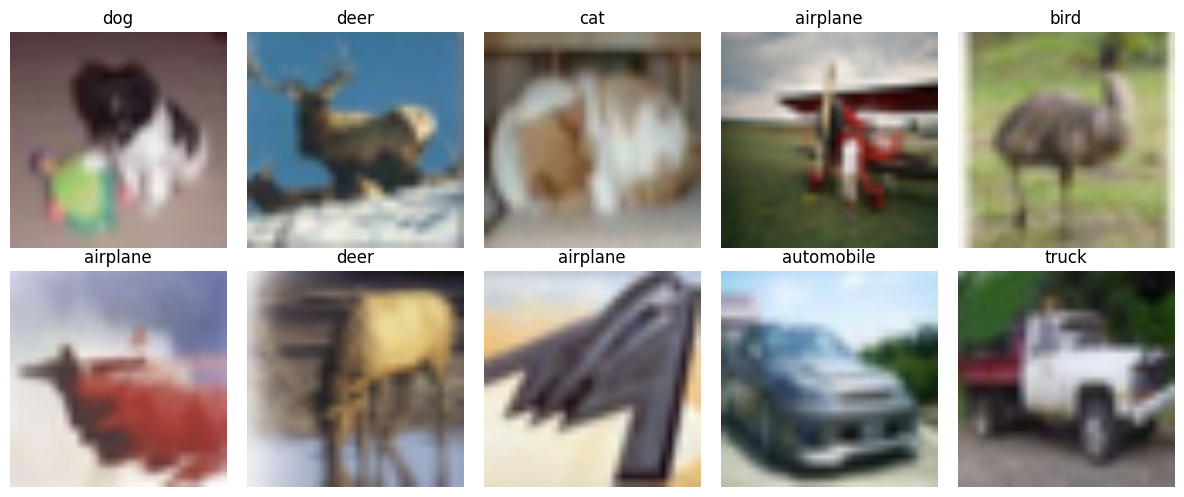

In [5]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0).numpy()
    img = np.clip(img * std + mean, 0, 1)

    ax.imshow(img)
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=10,
    ignore_mismatched_sizes=True
)

vit_model = vit_model.to(device)

# Freeze the pre-trained transformer encoder
for param in vit_model.vit.parameters():
    param.requires_grad = False

# Train only the classification head
vit_optimizer = torch.optim.AdamW(
    vit_model.classifier.parameters(), lr=1e-3
)

print("ViT model loaded successfully")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model loaded successfully


In [7]:
cnn_model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze the pre-trained convolutional layers
for param in cnn_model.parameters():
    param.requires_grad = False

# Replace classifier
cnn_model.fc = nn.Linear(cnn_model.fc.in_features, 10)

cnn_model = cnn_model.to(device)

cnn_optimizer = torch.optim.Adam(
    cnn_model.fc.parameters(), lr=1e-3
)

print("CNN model loaded successfully")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s]


CNN model loaded successfully


In [8]:
def train_model(model, optimizer, model_name, epochs=3):
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        print(
            f"{model_name} | Epoch {epoch+1}/{epochs} | "
            f"Loss: {running_loss/len(train_loader):.4f} | "
            f"Accuracy: {100*correct/total:.2f}%"
        )

print("Training ViT...")
train_model(vit_model, vit_optimizer, "ViT")

print("\nTraining CNN...")
train_model(cnn_model, cnn_optimizer, "ResNet-18")

Training ViT...
ViT | Epoch 1/3 | Loss: 0.3801 | Accuracy: 88.60%
ViT | Epoch 2/3 | Loss: 0.2091 | Accuracy: 93.27%
ViT | Epoch 3/3 | Loss: 0.1686 | Accuracy: 94.50%

Training CNN...
ResNet-18 | Epoch 1/3 | Loss: 1.1488 | Accuracy: 64.23%
ResNet-18 | Epoch 2/3 | Loss: 0.7530 | Accuracy: 75.41%
ResNet-18 | Epoch 3/3 | Loss: 0.6705 | Accuracy: 77.74%


In [9]:
def evaluate_model(model, model_name):
    model.eval()
    y_true = []
    y_pred = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    results = {
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Inference (ms/image)": elapsed / len(y_true) * 1000
    }

    print(f"\n{model_name} Classification Report:")
    print(classification_report(
        y_true, y_pred, labels=list(range(10)),
        target_names=classes, zero_division=0
    ))

    return results, y_true, y_pred


vit_results, y_true, vit_pred = evaluate_model(vit_model, "ViT")
cnn_results, _, cnn_pred = evaluate_model(cnn_model, "ResNet-18")


ViT Classification Report:
              precision    recall  f1-score   support

    airplane       0.88      0.95      0.91       196
  automobile       0.96      0.94      0.95       198
        bird       0.96      0.93      0.95       195
         cat       0.86      0.92      0.89       199
        deer       0.96      0.95      0.96       198
         dog       0.90      0.85      0.88       185
        frog       0.95      0.97      0.96       216
       horse       0.97      0.95      0.96       193
        ship       0.99      0.94      0.96       217
       truck       0.94      0.95      0.94       203

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000


ResNet-18 Classification Report:
              precision    recall  f1-score   support

    airplane       0.80      0.70      0.75       196
  automobile       0.88      0.88      0.88       198
        bird    

In [10]:
import pandas as pd

results_df = pd.DataFrame([vit_results, cnn_results])

print("Performance Comparison:")
display(results_df.round(2))

Performance Comparison:


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Inference (ms/image)
0,ViT,93.65,93.72,93.57,93.60,11.28
1,ResNet-18,77.60,77.88,77.55,77.38,1.78


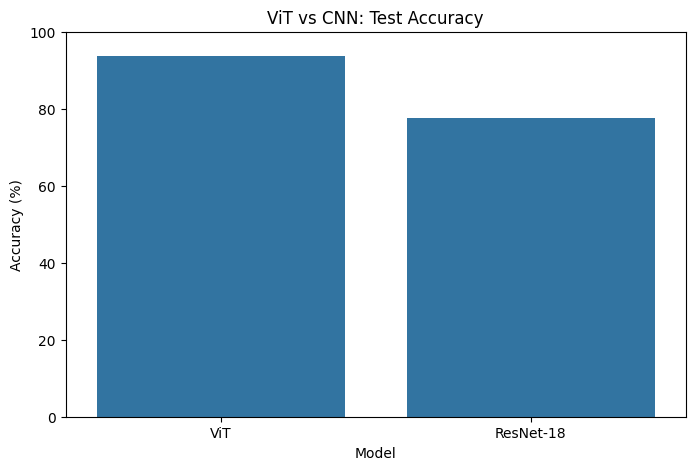

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title("ViT vs CNN: Test Accuracy")
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.show()

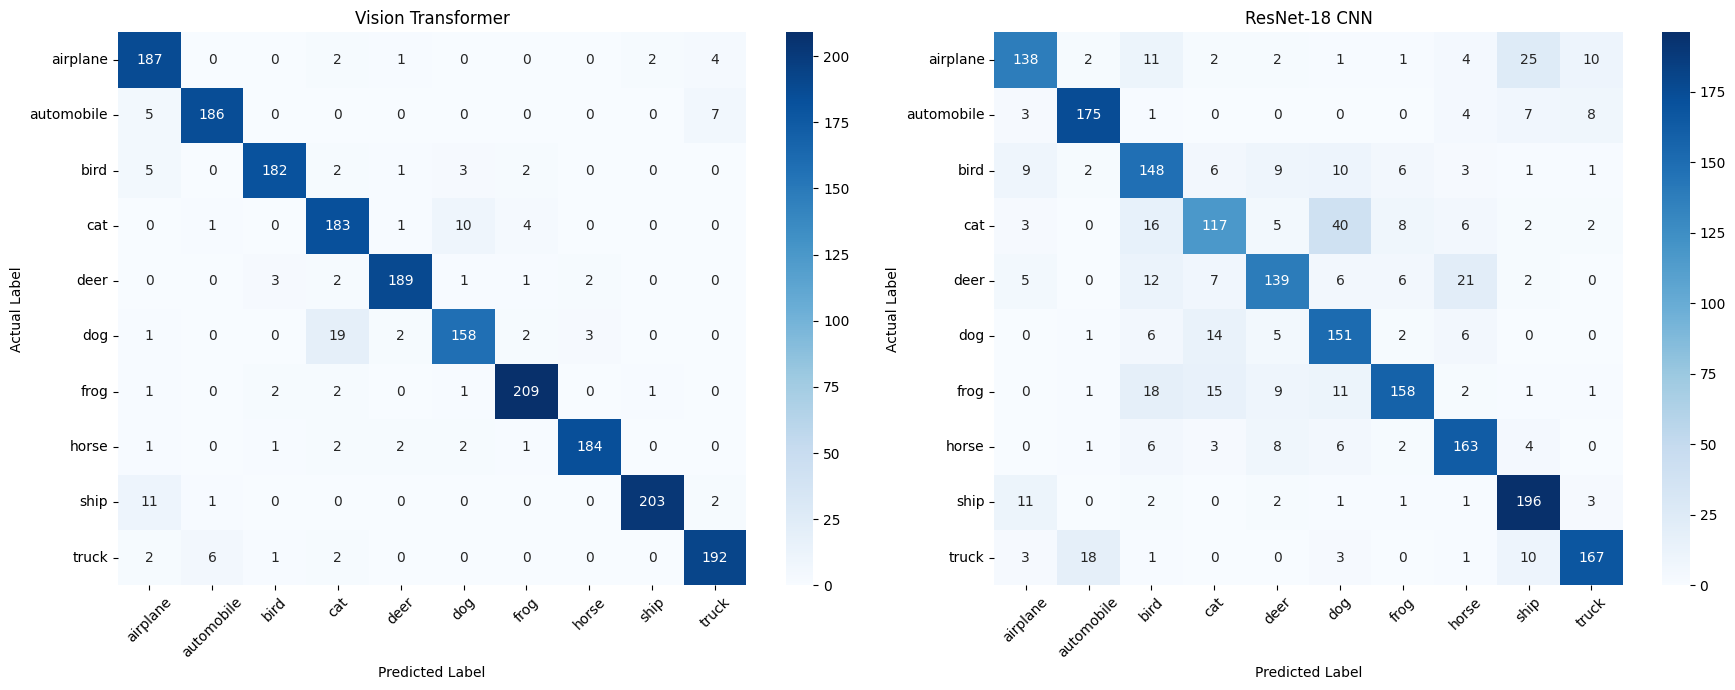

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, predictions, name in [
    (axes[0], vit_pred, "Vision Transformer"),
    (axes[1], cnn_pred, "ResNet-18 CNN")
]:
    cm = confusion_matrix(y_true, predictions, labels=range(10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

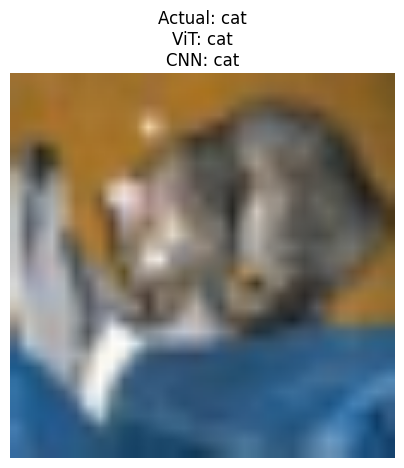

In [13]:
def predict_image(index=0):
    image, label = test_dataset[index]
    batch = image.unsqueeze(0).to(device)

    vit_model.eval()
    cnn_model.eval()

    with torch.no_grad():
        vit_output = vit_model(batch).logits
        cnn_output = cnn_model(batch)

    vit_prediction = vit_output.argmax(1).item()
    cnn_prediction = cnn_output.argmax(1).item()

    img = image.permute(1, 2, 0).cpu().numpy()
    img = np.clip(img * std + mean, 0, 1)

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(
        f"Actual: {classes[label]}\n"
        f"ViT: {classes[vit_prediction]}\n"
        f"CNN: {classes[cnn_prediction]}"
    )
    plt.axis("off")
    plt.show()

predict_image(0)